This notebook analyzes the weak stationarity of time series using the NTRfC package. Weak stationarity is present when the mean and variance of a time series remain constant over time. This property is crucial for many statistical methods and modeling approaches.

Approach

The code utilizes rolling data frames to determine an "optimal" reference window at the end of the time series. This window serves as a comparison baseline for the preceding part of the time series in terms of mean and variance.

Additionally, a Z-score normalization (mean=0, var=1) of the time series is performed based on the reference window. This makes the algorithm more robust to scaling effects caused by different trends.

Sensitivity

The algorithm is highly sensitive and can detect even small deviations in mean and variance. Therefore, it is particularly suitable for detailed analyses of time series data where subtle changes are of interest.

In [146]:
from ntrfc.timeseries.stationarity import estimate_stationarity
import numpy as np
import matplotlib.pyplot as plt

Generate a synthetic signal to illustrate the effect of the stationarity index

In [147]:
def signal_generator(amplitude=1, frequency=1, mean=0, abate=None, noise_amplitude=0.0, time=10.0, resolution=128):
    step = time * (frequency * resolution)
    times = np.linspace(0, time, step)
    noise = np.random.normal(-1, 1, len(times)) * noise_amplitude if noise_amplitude else 0
    decay = np.e ** -(times * abate) if abate else 0
    values = amplitude * np.sin(frequency * times* (np.pi*2)) + mean + decay + noise
    return times, values

In [148]:
def plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty):
    f,axs = plt.subplots(2,1)
    axs[0].plot(timesteps, values, label="f",linewidth=2)
    if stationary_timestep is not None:
        statmean = np.mean(values[stationary_timestep:])
        axs[0].axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
        axs[0].axhline(y=statmean,xmin=timesteps[stationary_timestep], color="red", label=f"mean: {statmean}")
        axs[0].axhline(y=statmean+mean_uncertainty,xmin=timesteps[stationary_timestep], color="grey", linestyle="--", label=f"uncertainty: {mean_uncertainty}")
        axs[0].axhline(y=statmean-mean_uncertainty,xmin=timesteps[stationary_timestep], color="grey", linestyle="--")

                # Unsicherheit als schattierte Fläche
        axs[0].fill_between(
            timesteps[stationary_timestep:],
            values[stationary_timestep:] - mean_uncertainty,
            values[stationary_timestep:] + mean_uncertainty,
            color="grey", alpha=0.6, label="uncertainty"
        )


        axs[1].plot(timesteps[stationary_timestep:], values[stationary_timestep:], label="f",linewidth=2)
        axs[1].axhline(y=statmean,xmin=timesteps[stationary_timestep], color="red", label=f"mean: {statmean}")
        axs[1].axhline(y=statmean+mean_uncertainty,xmin=timesteps[stationary_timestep], color="grey", linestyle="--", label=f"uncertainty: {mean_uncertainty}")
        axs[1].axhline(y=statmean-mean_uncertainty,xmin=timesteps[stationary_timestep], color="grey", linestyle="--")
        axs[1].fill_between(
            timesteps[stationary_timestep:],
            values[stationary_timestep:] - mean_uncertainty,
            values[stationary_timestep:] + mean_uncertainty,
            color="grey", alpha=0.6, label="uncertainty"
        )
        axs[1].set_title(f"stationary signal")
        axs[1].grid()
        axs[1].legend()

    axs[0].set_title(f"estimate_stationarity {stationary_timestep}")
    axs[0].grid()
    axs[0].legend()



    plt.tight_layout()
    plt.show()

The optimal time window balances trend sensitivity with minimal mean and variance error, depending on noise, trend, and autocorrelation. The algorithm requires at least four periods of a sinusoidal signal to detect stationarity. Reference windows ranging from 10% to 50% of the total signal length are allowed.

To evaluate mean and variance uncertainty using a rolling dataframe, at least two periods are required, since a time series of length nn with a window size ww results in mean and variance time series of size n−w.

For asymptotic functions, the algorithm will select the smallest possible reference window to minimize mean error. The algorithm is sensitive to linear and nonlinear trends.

In the case of a noisy signal, the optimal time window will be larger, as uncertainties are minimized through better statistical convergence.

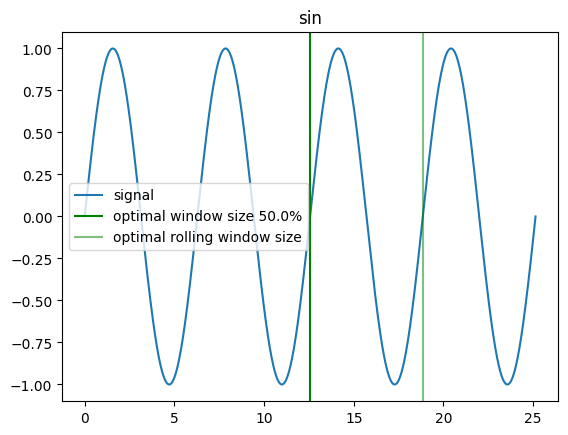

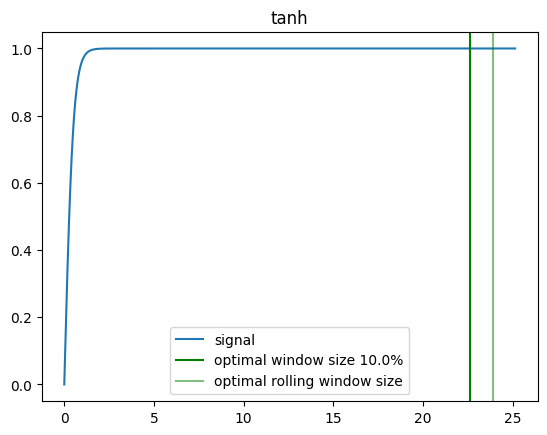

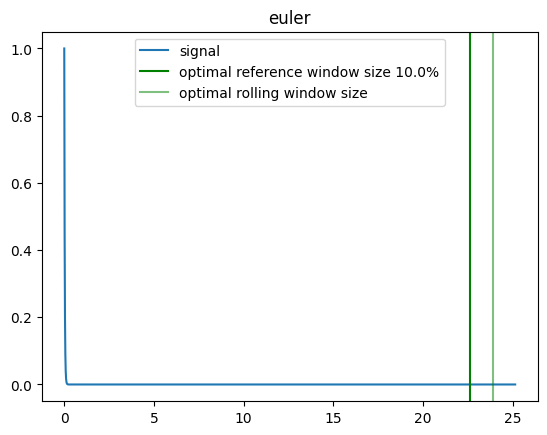

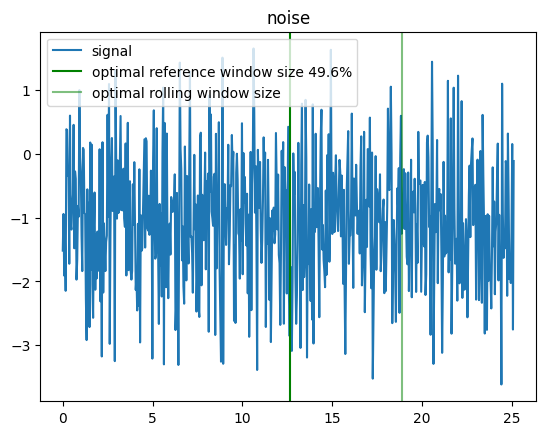

In [149]:
from ntrfc.timeseries.stationarity import optimal_window_size
# sine
res = 10000

nper = 4
x = np.linspace(0, 2 * np.pi * nper, res)

# sin
# we have four periods, at least one period should be captured
# thats res // 4 as a return
ysin = np.sin(x)
opt_window, opt_window_size, _ = optimal_window_size(ysin)

f,axs = plt.subplots(1,1)
axs.plot(x, ysin, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label=f"optimal window size {2*opt_window_size/len(x) * 100}%")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green",alpha=0.5, label="optimal rolling window size")
axs.set_title("sin")
axs.legend()
plt.show()

# tanh
tanh = np.tanh(x * 2)
opt_window, opt_window_size, _ = optimal_window_size(tanh)

f,axs = plt.subplots(1,1)
axs.plot(x, tanh, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label=f"optimal window size {2*opt_window_size/len(x) * 100}%")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green",alpha=0.5, label="optimal rolling window size")
axs.set_title("tanh")
axs.legend()
plt.show()
# euler
eul = np.e ** (-x * 40)
opt_window, opt_window_size, _ = optimal_window_size(eul)

f,axs = plt.subplots(1,1)
axs.plot(x, eul, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label=f"optimal reference window size {2*opt_window_size/len(x) * 100}%")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green", alpha=0.5, label="optimal rolling window size")
axs.set_title("euler")
axs.legend()
plt.show()

t = x[::16]

noise = np.random.normal(-1, 1, len(t))
opt_window, opt_window_size, _ = optimal_window_size(noise)
f,axs = plt.subplots(1,1)
axs.plot(t, noise, label="signal")
axs.axvline(x=t[-2*opt_window_size],ymin=-1,ymax=1, color="green", label=f"optimal reference window size {2*opt_window_size/len(t) * 100}%")
axs.axvline(x=t[-opt_window_size],ymin=-1,ymax=1, color="green", alpha=0.5, label="optimal rolling window size")
axs.set_title("noise")
axs.legend()
plt.show()


A sine wave is considered stationary, given that its mean remains constant when referenced to an appropriate window size. The wave's shape is consistent with low noise, ensuring high confidence in stationarity when the mean is evaluated over a suitable reference window size.

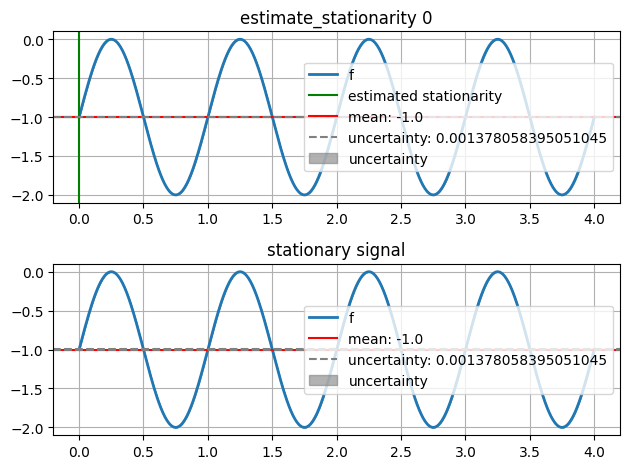

In [150]:
amplitude = 1 # 1,10
frequency = 1  # 1,10
time = 4 # 10, 60
mean = -1  # -1,0,1

timesteps, values = signal_generator(amplitude=amplitude, frequency=frequency, mean=mean, time=time)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)

If a noiseless signal contains a step, the segment following the step can be considered stationary, regardless of the magnitude of the step if the statistical properties remain constant after the step change.

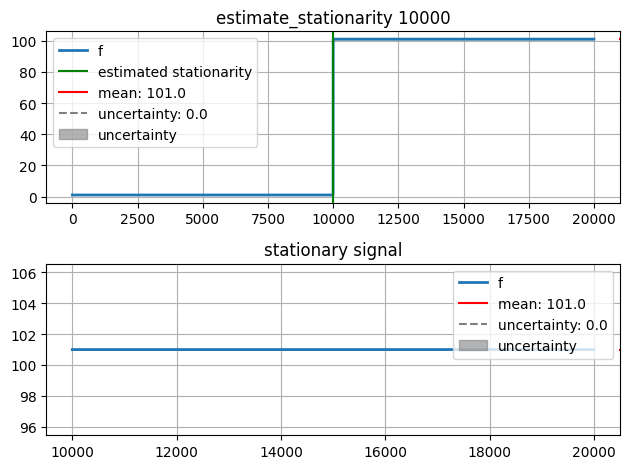

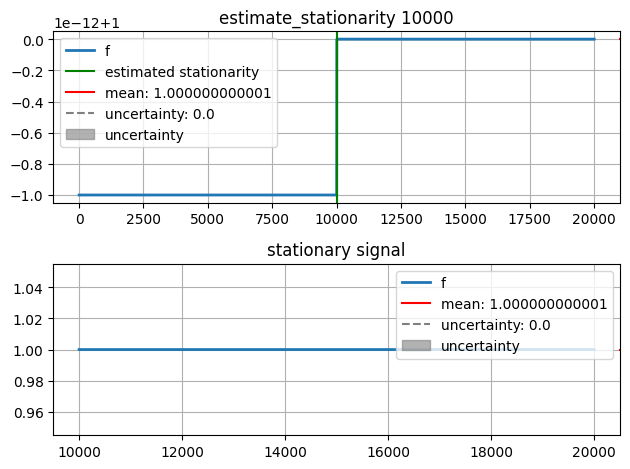

In [151]:
res = 20000

snr_false = 1e2
signal_amplitude = 1
values_stationary = signal_amplitude * np.ones(res)
stepsize = snr_false / signal_amplitude
values_stationary[res//2:] = 1 + stepsize
stationary_timestep_false ,_,mean_uncertainty= estimate_stationarity(values_stationary)
timesteps = np.arange(0,res)

plot_estimate(timesteps, values_stationary, stationary_timestep_false,mean_uncertainty)

snr = 1e-12
stepsize = snr / signal_amplitude
values_stationary = np.ones(res) * signal_amplitude
values_stationary[res // 2:] = 1 + stepsize
timesteps = np.arange(0,len(values_stationary))
stationary_timestep_true,_,mean_uncertainty= estimate_stationarity(values_stationary)


plot_estimate(timesteps, values_stationary, stationary_timestep_true,mean_uncertainty)

A linear function with a trend is not considered stationary, as its statistical properties change over time. The optimal_window algorithm detects these trends through normalization, identifying any trend regardless of the gradient, which causes it to return 'False' for stationarity.

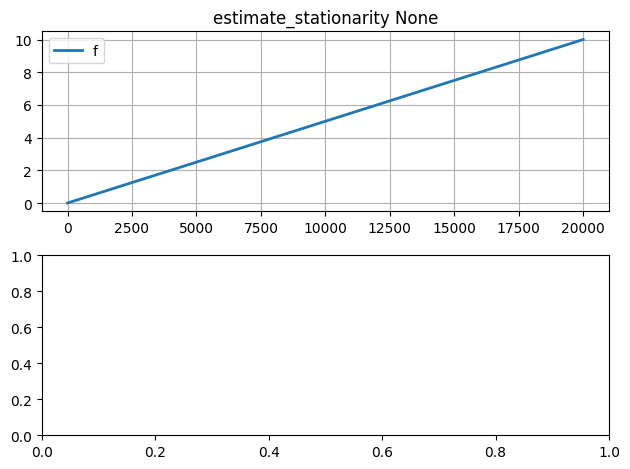

In [152]:
res = 20000

values_high = np.linspace(0, 10, res)

answer,_,mean_uncertainty=  estimate_stationarity(values_high)

plot_estimate(np.arange(0,res), values_high, answer,mean_uncertainty)


Both signals contain noise and a ramp segment. A ramp is always considered non-stationary, regardless of the noise level because of the normalization.

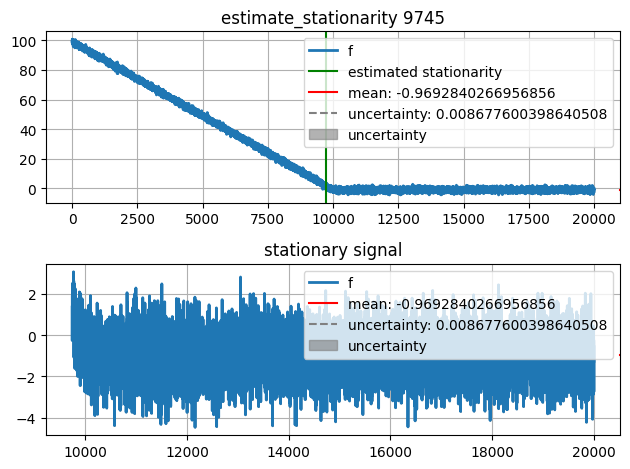

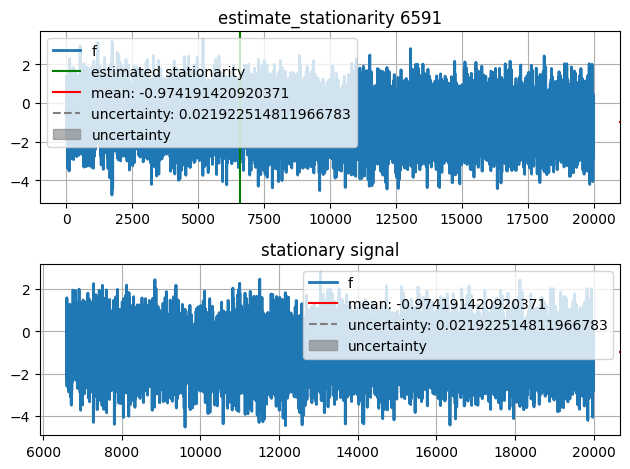

In [153]:
res = 20000
noise_amplitude = 1
snr = 100
ramp_amplitude = noise_amplitude * snr
timesteps = np.arange(0,res)
noise = np.random.normal(-1, 1, res) * noise_amplitude

values_stationary = np.zeros(res) + noise
values_stationary[:res//2] = values_stationary[:res//2] + np.linspace(ramp_amplitude, 0, res//2)
stationary_timestep_true  ,_,mean_uncertainty= estimate_stationarity(values_stationary)

plot_estimate(timesteps, values_stationary, stationary_timestep_true,mean_uncertainty)



snr = 0.5
ramp_amplitude = noise_amplitude * snr
values_stationary_new = np.zeros(res) + noise

values_stationary_new[:res//2] =values_stationary_new[:res//2]+  np.linspace(ramp_amplitude, 0, res//2)
stationary_timestep_false  ,_,mean_uncertainty= estimate_stationarity(values_stationary_new)


plot_estimate(timesteps, values_stationary_new, stationary_timestep_false,mean_uncertainty)

Noise is considered stationary or non-stationary depending on the sample size.

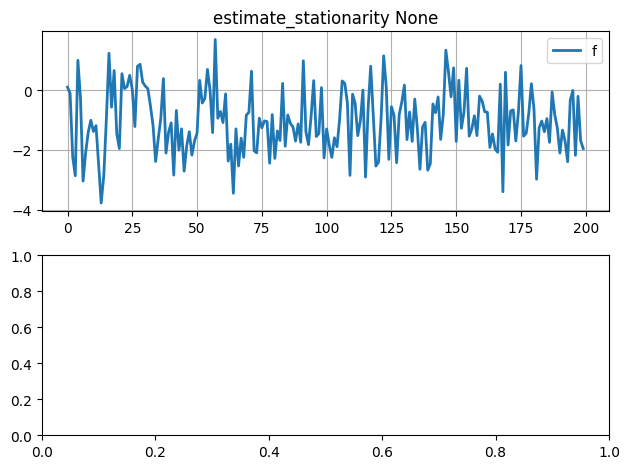

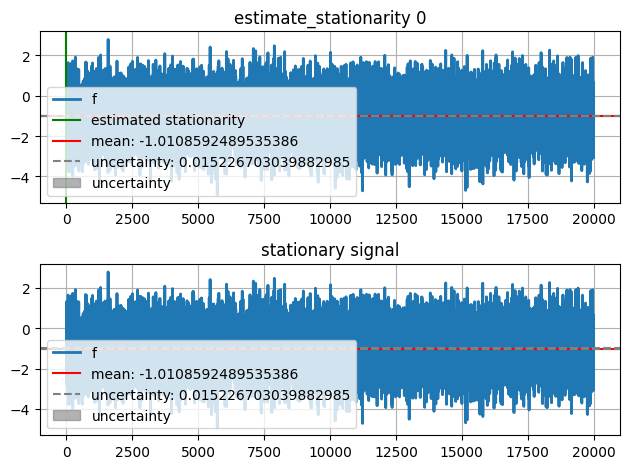

In [154]:
res = 200

values = np.random.normal(-1, 1, res)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)
timesteps = np.arange(0,res)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)


res = 20000
timesteps = np.arange(0,res)

values = np.random.normal(-1, 1, res)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)

Nonlinear trends will be detected.

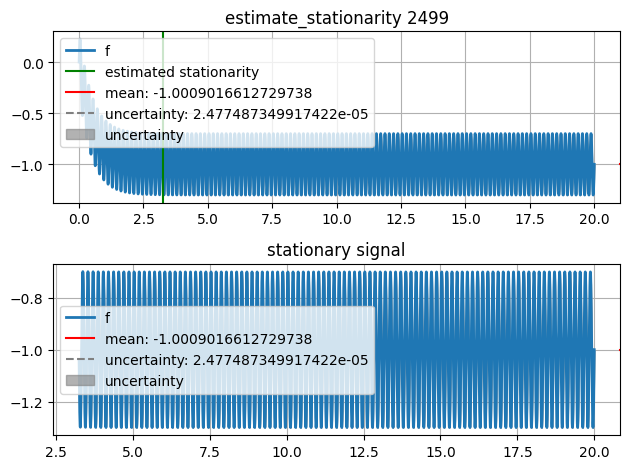

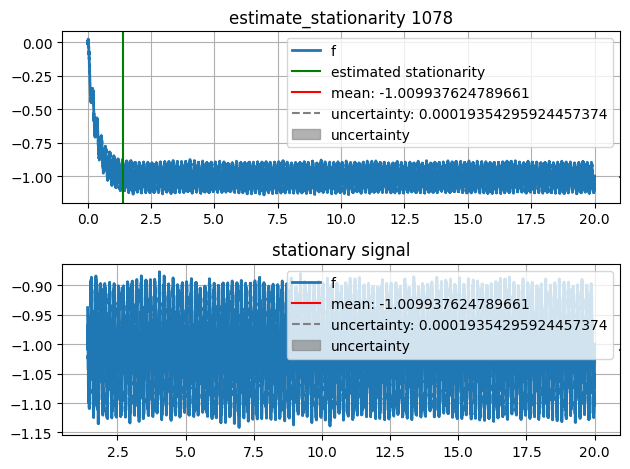

In [155]:
amplitude = 0.3
frequency = 6
time = 20
mean = -1
abate = 2

timesteps, values = signal_generator(amplitude=amplitude, frequency=frequency, mean=mean, time=time,
                                          abate=abate)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)

amplitude = 0.1
noiseamplitude = 0.01
frequency = 6
time = 20
mean = -1
abate = 3

timesteps, values = signal_generator(amplitude=amplitude, noise_amplitude=noiseamplitude,
                                          frequency=frequency, mean=mean, time=time,
                                          abate=abate)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)

A signal with varying variance is considered non-stationary, as its statistical properties change over time.

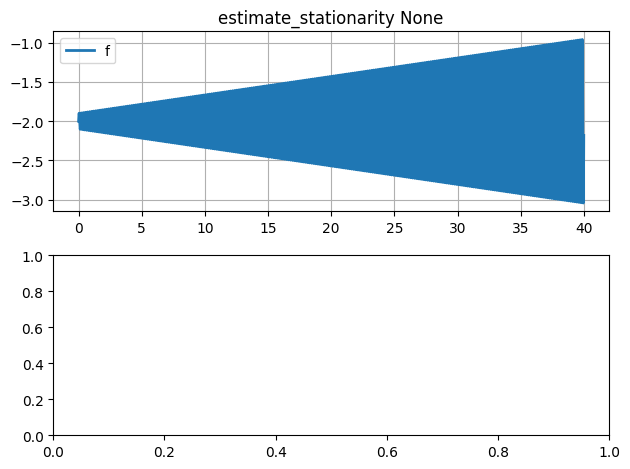

In [156]:

def signalgen_abatingsine(amplitude, frequency, mean, time):
    resolution = 36
    step = (1 / frequency) / resolution

    times = np.arange(0, time, step)

    values = (amplitude + frequency * (2 * np.pi) * times / 1600) * np.sin(frequency * (2 * np.pi) * times) + mean
    return times, values

amplitude = 0.1
frequency = 6
time = 40
mean = -2

timesteps, values = signalgen_abatingsine(amplitude=amplitude,
                                          frequency=frequency, mean=mean, time=time)

stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)

A constant signal is considered stationary, as its mean and variance remain unchanged. The algorithm can handle zero variance cases.

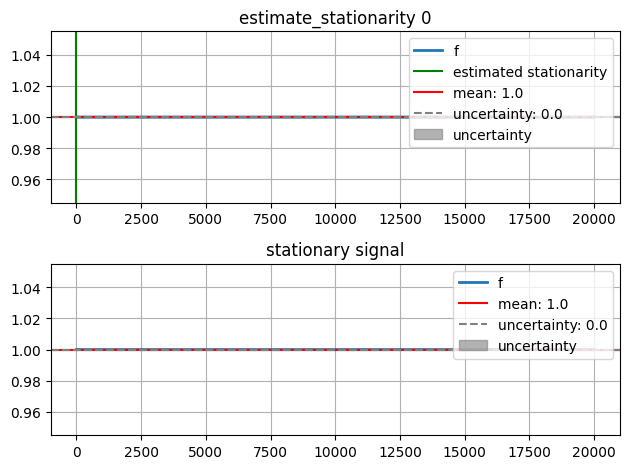

In [157]:
res = 20000
timesteps = np.arange(0,res)
values_stationary = np.ones(res)
stationary_timestep  ,_,mean_uncertainty= estimate_stationarity(values_stationary)


plot_estimate(timesteps, values_stationary, stationary_timestep,mean_uncertainty)

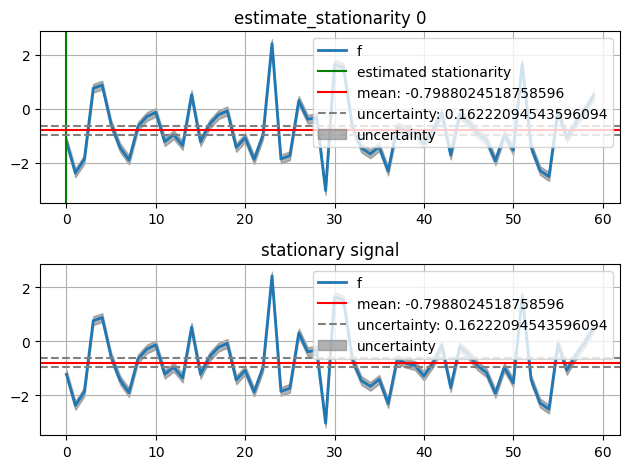

In [158]:
res = 60

values = np.random.normal(-1, 1, res)
stationary_timestep ,_,mean_uncertainty= estimate_stationarity(values,mean_error=0.05,var_error=0.05)
timesteps = np.arange(0,res)

plot_estimate(timesteps, values, stationary_timestep,mean_uncertainty)